# WP13 — Gerçek DB14569 B1 dış tahmini v1

**EXPLORATORY_EXTERNAL_LABEL_ISOLATED**. Önceki STRICT_ANALYST_BLINDNESS_COMPROMISED sınırlaması korunur. Bu defter yalnız hash ile kilitlenmiş çıktıları okur; model forward/fit, yeni SHAP, API veya referans belgesi erişimi yoktur. Skorlar SIDER observed-record proxy; klinik olasılık/sıklık/kalibrasyon değildir. Unknown çiftler biyolojik negatif değildir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/tedizolid_B1_external_v1';F=ROOT/'reports/figures/WP13/tedizolid_B1_external_v1'
lock=json.loads((Q/'prediction_lock.json').read_text(encoding='utf-8'));pre=json.loads((Q/'precommit_manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:lock[k] for k in ['experiment_status','drug_id','query_count','forward_calls','common_targets','DB09042','stress','A1P1','SHAP','reference_access']}]).T)
display(pd.read_csv(Q/'coverage_summary.csv'))
display(pd.read_json(Q/'active_input.json',typ='series').to_frame('onaylı_girdi'))


,0
experiment_status,EXPLORATORY_EXTERNAL_LABEL_ISOLATED
drug_id,DB14569
query_count,1
forward_calls,5
common_targets,201
DB09042,NOT_RUN
stress,NOT_RUN
A1P1,NOT_RUN
SHAP,DEFERRED_NOT_RUN
reference_access,False


,fold,valid_PT,common_PT,outside_common_PT,query,scope
0,1,220,201,19,DB14569,primary B1; NOT OOF; external label-isolated exploratory
1,2,262,201,61,DB14569,primary B1; NOT OOF; external label-isolated exploratory
2,3,267,201,66,DB14569,primary B1; NOT OOF; external label-isolated exploratory
3,4,270,201,69,DB14569,primary B1; NOT OOF; external label-isolated exploratory
4,5,275,201,74,DB14569,primary B1; NOT OOF; external label-isolated exploratory


,onaylı_girdi
drug_id,DB14569
representation,active_tedizolid
raw_smiles,CN1N=NC(=N1)C1=NC=C(C=C1)C1=C(F)C=C(C=C1)N1C[C@H](CO)OC1=O
InChIKey,XFALPSLJIHVRKE-GFCCVEGCSA-N
features,"{'MW': 370.34400000000016, 'LogP': 1.3957, 'HBD': 1.0, 'HBA': 7.0, 'TPSA': 106.26000000000002}"
units,"[g/mol, dimensionless Crippen LogP, count, count, angstrom^2]"
chemistry_available,True
descriptor_definition,WP04 descriptors: MolWt/MolLogP/NumHDonors/NumHAcceptors/CalcTPSA(includeSandP=False); no fragme...
rdkit_version,2026.09.1
source_provenance,accepted local DrugBank XML SMILES; preparation source CSV SHA pinned


**Yorum:** Tek dış aktif-molekül query, önceden seçilmiş beş primary model. Ön ilaç/stress/GNN NOT_RUN. Beş modelin tüm geçerli1294 skor kaydı korunur; farklı başlıklar sıfırla doldurulmaz. Bu drug-disjoint OOF değil, yeni ve etiketten yalıtılmış dış araştırma query'sidir.

,rank,class_id,record_ranking_score,drug_id,contributing_models,aggregation,semantics,fold1_score,fold2_score,fold3_score,fold4_score,fold5_score
0,1,C0011991,0.864200,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.795402,0.831542,0.955515,0.935704,0.802835
1,2,C0015230,0.855534,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.796102,0.804158,0.949028,0.935035,0.793345
2,3,C0002792,0.854920,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.783397,0.787826,0.957617,0.954742,0.791019
3,4,C0042963,0.847858,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.787195,0.794642,0.939465,0.935035,0.782955
4,5,C0000737,0.823995,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.770632,0.790163,0.893630,0.925255,0.740298
5,6,C0687713,0.823995,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.770632,0.790163,0.893630,0.925255,0.740298
6,7,C0020517,0.821030,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.735233,0.775761,0.929452,0.922165,0.742536
7,8,C0033774,0.817670,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.742175,0.769744,0.915099,0.905413,0.755918
8,9,C0040034,0.816634,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.741503,0.777689,0.881003,0.911695,0.771280
9,10,C0042109,0.805517,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.738500,0.775830,0.875415,0.890580,0.747259


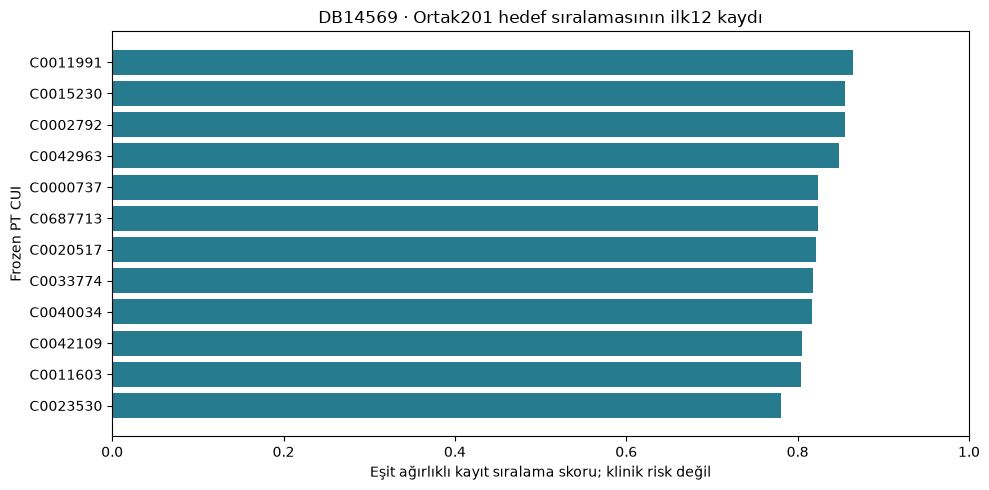

In [2]:

common=pd.read_csv(Q/'common201_scores.csv',float_precision='round_trip')
display(common.head(15))
fig,ax=plt.subplots(figsize=(10,5));top=common.head(12).iloc[::-1];ax.barh(top.class_id,top.record_ranking_score,color='#277b8e');ax.set(xlabel='Eşit ağırlıklı kayıt sıralama skoru; klinik risk değil',ylabel='Frozen PT CUI',title='DB14569 · Ortak201 hedef sıralamasının ilk12 kaydı',xlim=(0,1));plt.tight_layout();plt.savefig(F/'01_common201_record_ranking.png',dpi=170);plt.show()


**Yorum:** Aritmetik ortalama beş SIGMOID skorundadır; logit ortalaması değildir. Grafik yalnız yeni dosyanın sıralamasını gösterir; başarı, görülme sıklığı veya klinik risk sonucu çıkarılmaz. PT adlandırmak için bu tur dış referans veya prospektüs açılmadı; hedefler modelin sabit CUI'leridir.

,rank,class_id,record_ranking_score,logit
0,1,C0027497,0.804376,1.413872
1,2,C0015230,0.796102,1.362106
2,3,C0011991,0.795402,1.357799
3,4,C0042963,0.787195,1.308102
4,5,C0002792,0.783397,1.285574
5,6,C0000737,0.770632,1.211882
6,7,C0687713,0.770632,1.211882
7,8,C0011603,0.744465,1.069306


,rank,class_id,record_ranking_score,logit
0,1,C0011991,0.831542,1.596599
1,2,C0015230,0.804158,1.412487
2,3,C0027497,0.804158,1.412487
3,4,C0042963,0.794642,1.353138
4,5,C0000737,0.790163,1.325911
5,6,C0687713,0.790163,1.325911
6,7,C0002792,0.787826,1.311869
7,8,C0040034,0.777689,1.252248


,rank,class_id,record_ranking_score,logit
0,1,C0002792,0.957617,3.117703
1,2,C0011991,0.955515,3.067105
2,3,C0015230,0.949028,2.924170
3,4,C0042963,0.939465,2.742084
4,5,C0020517,0.929452,2.578302
5,6,C0033774,0.915099,2.377544
6,7,C0000737,0.893630,2.128365
7,8,C0687713,0.893630,2.128365


,rank,class_id,record_ranking_score,logit
0,1,C0002792,0.954742,3.049061
1,2,C0027497,0.942111,2.789603
2,3,C0011991,0.935704,2.677801
3,4,C0015230,0.935035,2.666736
4,5,C0042963,0.935035,2.666736
5,6,C0000737,0.925255,2.515985
6,7,C0687713,0.925255,2.515985
7,8,C0020517,0.922165,2.472139


,rank,class_id,record_ranking_score,logit
0,1,C0027497,0.803383,1.407573
1,2,C0011991,0.802835,1.404110
2,3,C0015230,0.793345,1.345210
3,4,C0002792,0.791019,1.331078
4,5,C0042963,0.782955,1.282969
5,6,C0040034,0.771280,1.215551
6,7,C0011603,0.760219,1.153879
7,8,C0033774,0.755918,1.130429


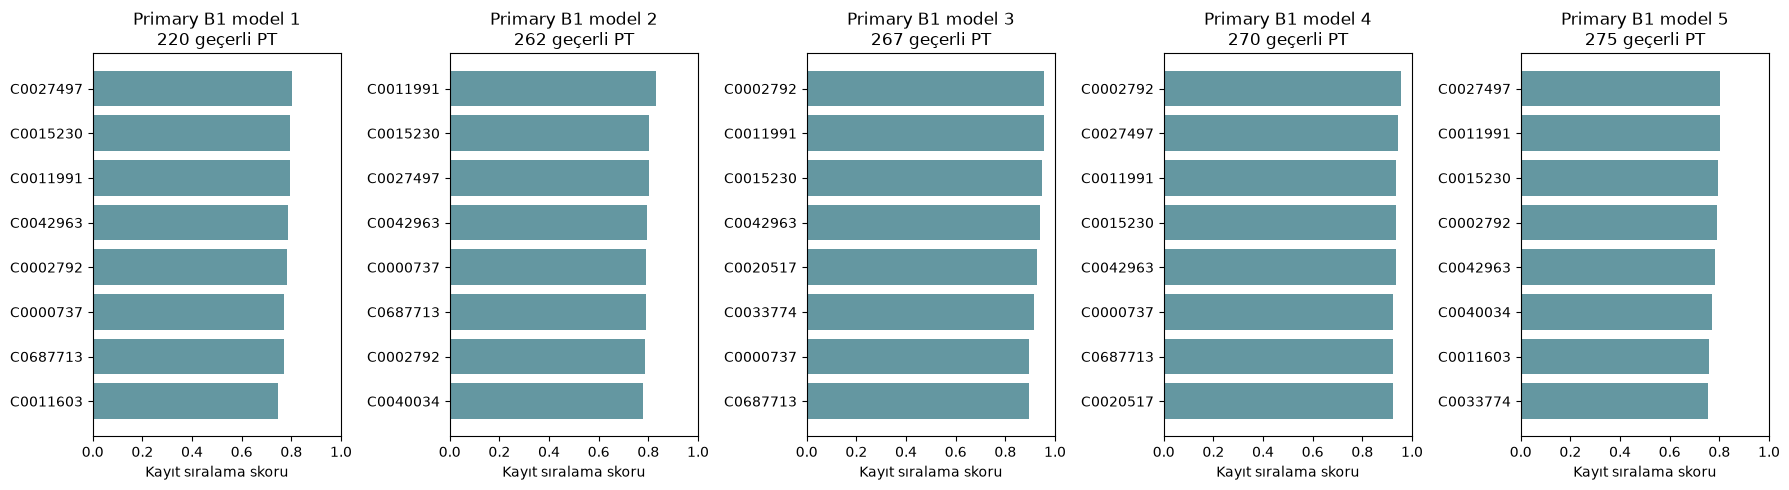

In [3]:

fig,axs=plt.subplots(1,5,figsize=(18,5),sharex=True)
for i,ax in enumerate(axs,1):
    f=pd.read_csv(Q/f'fold{i}_scores.csv');display(f[['rank','class_id','record_ranking_score','logit']].head(8))
    t=f.head(8).iloc[::-1];ax.barh(t.class_id,t.record_ranking_score,color='#6497a1');ax.set(title=f'Primary B1 model {i}\n{len(f)} geçerli PT',xlim=(0,1),xlabel='Kayıt sıralama skoru')
plt.tight_layout();plt.savefig(F/'02_five_individual_rankings.png',dpi=160);plt.show()


**Yorum:** Bireysel modeller kendi native hedef uzayındadır. Farklı başlıklar nedeniyle bu paneller farklı sayıda hedef taşır; ortalama yalnız ortak201'de yapılır. Model/fold seçiminde bu sonuçlar kullanılmadı.

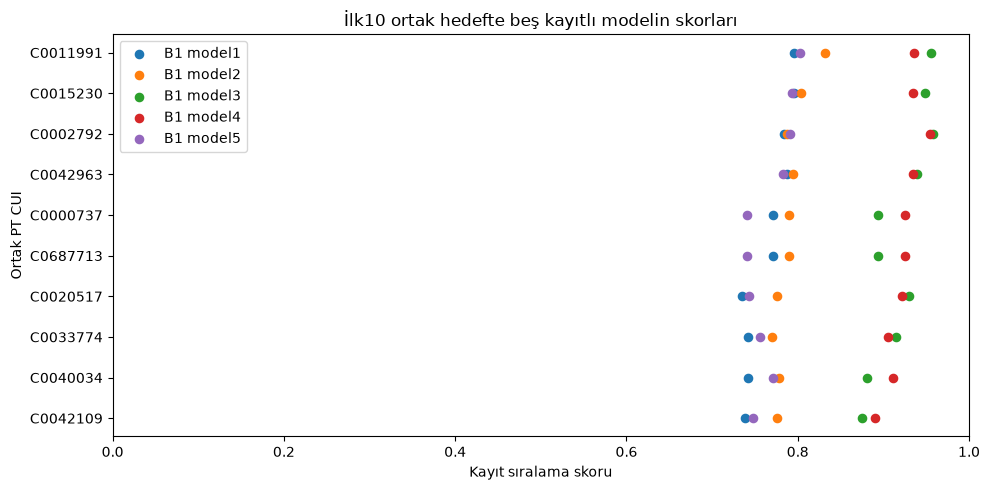

,fold,PT_count,finite_scores,sigmoid_logit_max_error
0,1,220,True,0
1,2,262,True,0
2,3,267,True,0
3,4,270,True,0
4,5,275,True,0


In [4]:

cols=[f'fold{i}_score' for i in range(1,6)]
t=common.head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,5))
for i,c in enumerate(cols,1):ax.scatter(t[c],t.class_id,label=f'B1 model{i}',s=35)
ax.set(xlabel='Kayıt sıralama skoru',ylabel='Ortak PT CUI',title='İlk10 ortak hedefte beş kayıtlı modelin skorları',xlim=(0,1));ax.legend();plt.tight_layout();plt.savefig(F/'03_common_target_model_spread.png',dpi=170);plt.show()
display(pd.read_json(Q/'numerical_checks.json'))


**Yorum:** Nokta yayılımı farklı donmuş train modellerinin aynı hedefe verdiği skorları gösterir; güven aralığı, bağımsız tekrar veya klinik belirsizlik ölçüsü değildir. Yeni SHAP DEFERRED_NOT_RUN; eski WP11 background/logit sözleşmesine uygun ayrı hesaplama ileride yapılabilir. Skor-ortalama ensemble'ı tek doğrusal logit modeli değildir; ortalama logit-SHAP doğrudan ensemble açıklaması yapılamaz. Prediction_lock sonrası da referans açılmadı. Bu aşama STOP; PDF karşılaştırması ayrı kullanıcı aşamasıdır.